# Classifying Brain Cancer Tumors With PyTorch

## VGG11_bn
- The VGG11_bn architecture has been shown to be effective in a wide range of image classification tasks, **including medical image analysis**. By fine-tuning the pre-trained weights of the VGG11_bn model on a dataset of MRI images, researchers can achieve high accuracy in detecting brain cancer tumors. This makes VGG11_bn a valuable tool for cancer researchers and clinicians seeking to improve the accuracy and efficiency of cancer diagnosis and treatment.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import copy
from time import time

import cv2
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
from torchvision.models import vgg11_bn, VGG11_BN_Weights
from sklearn.metrics import f1_score, classification_report

In [17]:
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
print(device)

cuda:0


### Augment Data

In [18]:
# define training transformations
train_transforms = transforms.Compose([
    transforms.ToTensor(),
    transforms.Resize((256, 256)),
    transforms.RandomResizedCrop(224),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
    transforms.RandomRotation(20),
    transforms.RandomHorizontalFlip()
])

# define testing and validation transformations
test_transformations = transforms.Compose([
    transforms.ToTensor(),
    transforms.Resize((256, 256)),
    transforms.CenterCrop(224),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])

### Create and Batch Datasets

In [19]:
# batch sets

train_loader = DataLoader(datasets.ImageFolder('../data/Training', transform=train_transforms) , batch_size=32, shuffle=True)
test_loader = DataLoader(datasets.ImageFolder('../data/Testing', transform=train_transforms), batch_size=32)

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-2.117904..2.64].


Feature batch shape: torch.Size([32, 3, 224, 224])
Labels batch shape: torch.Size([32])
torch.Size([3, 224, 224])


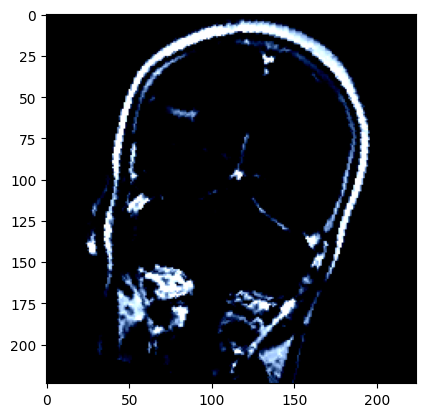

Label: 0


In [51]:
# Display image and label.
train_features, train_labels = next(iter(train_loader))
print(f"Feature batch shape: {train_features.size()}")
print(f"Labels batch shape: {train_labels.size()}")
img = train_features[0]
label = train_labels[0]
print(img.size())
# Convert from (C, H, W) to (H, W, C)
img = img.permute(1, 2, 0)
plt.imshow(img)
plt.show()
print(f"Label: {label}")

## Build Model

In [8]:
class Net(nn.Module):
    def __init__(self, num_classes):
        super(Net, self).__init__()

        # load in vgg
        vgg = vgg11_bn(weights='IMAGENET1K_V1')
        num_input_features = vgg.classifier[6].in_features

        # freeze layers
        for param in vgg.parameters():
            param.requires_grad = False

        # define feed forward network
        vgg.classifier[6] = nn.Linear(num_input_features, num_classes)
        for param in vgg.classifier.parameters():
            param.requires_grad = True
            
        self.model = vgg

    def forward(self, x):
        return self.model(x)

## Model Architecture

In [10]:
model

Net(
  (model): VGG(
    (features): Sequential(
      (0): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU(inplace=True)
      (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
      (4): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (5): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (6): ReLU(inplace=True)
      (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
      (8): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (9): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (10): ReLU(inplace=True)
      (11): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (12): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (

## Define Training Class

In [9]:
class BrainTumorClassification:
    def __init__(self, model, optimizer, loss_fn, val_transformations, classes, device):
        self.model = model
        self.optimizer = optimizer
        self.loss_fn = loss_fn
        self.history = {}
        self.val_transformations = val_transformations
        self.classes = classes
        self.device = device
        

    def _train_epoch(self, training_loader):
        running_loss = 0.00
        total_correct = 0
        total_samples = 0

        self.model.train()
        for imgs, labels in training_loader:

            # configure to device
            imgs, labels = imgs.to(self.device), labels.to(self.device)

            # zero out gradients
            self.optimizer.zero_grad()

            # forward pass
            outputs = self.model(imgs)
            loss = self.loss_fn(outputs, labels)

            # backward pass
            loss.backward()
            self.optimizer.step()

            # calculate loss of batch in average
            running_loss += loss.item()

            # calculate accuracy
            preds = torch.argmax(outputs, dim=1)
            n_correct = torch.sum(preds == labels)
            total_correct += n_correct
            total_samples += len(labels)

        running_loss /= len(training_loader)
        total_accuracy = float(total_correct / total_samples)

        return total_accuracy, running_loss

    @torch.no_grad()
    def _eval_epoch(self, eval_loader, return_metrics=True):
        
        running_loss = 0.00
        total_correct = 0
        total_samples = 0
        all_labels = []
        all_preds = []
        
        self.model.eval() 
        for imgs, labels in eval_loader:

            # configure to device
            imgs, labels = imgs.to(self.device), labels.to(self.device)

            # forward pass
            outputs = self.model(imgs)
            loss = self.loss_fn(outputs, labels)
            
            # Store predictions and actual labels
            preds = torch.argmax(outputs, dim=1)
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

            # calculate loss of batch in average
            running_loss += loss.item()

            # calculate accuracy
            preds = torch.argmax(outputs, dim=1)
            n_correct = torch.sum(preds == labels)
            total_correct += n_correct
            total_samples += len(labels)

        report = classification_report(
        all_labels,
        all_preds,
        labels=list(range(len(self.classes))),
        target_names=self.classes
        )
        running_loss /= len(eval_loader)
        total_accuracy = float(total_correct / total_samples)
        if return_metrics:
            return total_accuracy, running_loss, report

    def train(self, training_loader, eval_loader, num_epochs):

        # initialize metrics
        train_accuracies, train_losses = [], []
        val_accuracies, val_losses = [], []

        for epoch in range(num_epochs):
            print(f"Epoch {epoch+1}/{num_epochs}")

            # train one epoch
            train_acc, train_loss = self._train_epoch(training_loader)
            train_accuracies.append(train_acc)
            train_losses.append(train_loss)

            # eval one epoch
            val_acc, val_loss, report = self._eval_epoch(eval_loader)
            val_accuracies.append(val_acc)
            val_losses.append(val_loss)

            print("train accuracy = ",train_acc)
            print("test report: ")
            print(report)
            print("========================================")

        # end of training
        print('Training Finished!')

        # get history
        self.history = {
            'accuracy': {'train': train_accuracies, 'eval': val_accuracies},
            'loss': {'train': train_losses, 'eval': val_losses}
        }

    def plot_training(self):
 
        # Get the accuracy and loss values from self.history
        train_accuracies = self.history['accuracy']['train']
        val_accuracies = self.history['accuracy']['eval']
        train_losses = self.history['loss']['train']
        val_losses = self.history['loss']['eval']

        # Create subplots for accuracy and loss plots
        fig, axs = plt.subplots(2, 1, figsize=(10, 6))
        fig.subplots_adjust(hspace=0.5)

        # Plot training and validation accuracies
        axs[0].plot(train_accuracies, label='Training accuracy')
        axs[0].plot(val_accuracies, label='Validation accuracy')
        axs[0].set_title('Accuracy')
        axs[0].set_xlabel('Epoch')
        axs[0].set_ylabel('Accuracy')
        axs[0].legend()

        # Plot training and validation losses
        axs[1].plot(train_losses, label='Training loss')
        axs[1].plot(val_losses, label='Validation loss')
        axs[1].set_title('Loss')
        axs[1].set_xlabel('Epoch')
        axs[1].set_ylabel('Loss')
        axs[1].legend()

        plt.show()

    def evaluate(self, test_loader):

        return self._eval_epoch(test_loader, return_metrics=False)

    @torch.no_grad()
    def predict(self, img):

        self.model.eval()
        img = self.val_transformations(img)
        img = torch.unsqueeze(img, 0)
        img = img.to(self.Config.device)
        pred = self.model(img)
        pred_idx = torch.argmax(pred, dim=1)
        return self.classes[pred_idx]

## Train Model

In [10]:
# initialize params
model = Net(num_classes=4).to(device)
optimizer = optim.Adam(model.parameters(), lr=.001)
loss_fn = nn.CrossEntropyLoss()
classes = datasets.ImageFolder('../data/Training', transform=train_transforms).classes

# initialize classifier
classifier = BrainTumorClassification(
    model, 
    optimizer, 
    loss_fn,
    test_transformations,
    classes,
    device
)

# run training loop
t1 = time()
classifier.train(
    training_loader=train_loader,
    eval_loader=test_loader,
    num_epochs=10,
)
t2 = time()
print("Time of training: ", (t2-t1)/60,' minutes')

Epoch 1/10
train accuracy =  0.643750011920929
test report: 
              precision    recall  f1-score   support

      glioma       0.75      0.57      0.65       400
  meningioma       0.58      0.60      0.59       400
     notumor       0.81      0.91      0.85       400
   pituitary       0.77      0.83      0.80       400

    accuracy                           0.73      1600
   macro avg       0.73      0.73      0.72      1600
weighted avg       0.73      0.73      0.72      1600

Epoch 2/10
train accuracy =  0.7294642925262451
test report: 
              precision    recall  f1-score   support

      glioma       0.64      0.74      0.69       400
  meningioma       0.68      0.41      0.51       400
     notumor       0.79      0.92      0.85       400
   pituitary       0.77      0.82      0.79       400

    accuracy                           0.72      1600
   macro avg       0.72      0.73      0.71      1600
weighted avg       0.72      0.72      0.71      1600

Epoch 3

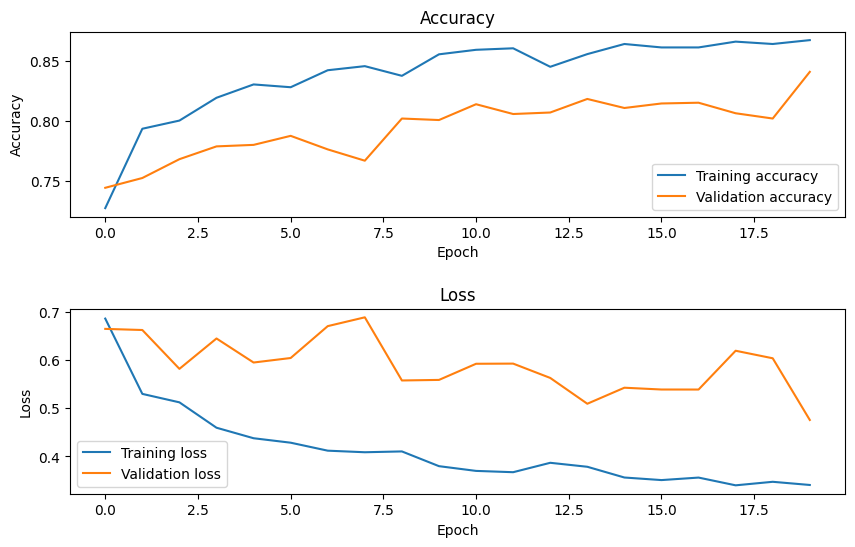

In [9]:
classifier.plot_training()

## Save Model

In [13]:
torch.save(model.state_dict(), 'pytorch_model_weights.pt')

In [14]:
# Save the entire model object
torch.save(model, 'pytorch_model.pt')

## Load Model

In [8]:
import torch
import torch.nn as nn
from torchvision import models

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

loaded_model = vgg11_bn(weights=None)
num_input_features = loaded_model.classifier[6].in_features
loaded_model.classifier[6] = nn.Linear(num_input_features, 4)

state_dict = torch.load(
    "..\model\pytorch_model_weights.pt",
    map_location=device,
    weights_only=True
)

state_dict = {
    key.replace("model.", "", 1): value
    for key, value in state_dict.items()
}

loaded_model.load_state_dict(state_dict)
loaded_model = loaded_model.to(device)
loaded_model.eval()

<>:12: SyntaxWarning: invalid escape sequence '\m'
<>:12: SyntaxWarning: invalid escape sequence '\m'
C:\Users\body2\AppData\Local\Temp\ipykernel_26612\1220919760.py:12: SyntaxWarning: invalid escape sequence '\m'
  "..\model\pytorch_model_weights.pt",


VGG(
  (features): Sequential(
    (0): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (5): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): ReLU(inplace=True)
    (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (8): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (9): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (10): ReLU(inplace=True)
    (11): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (12): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (13): ReLU(inplace=True)
    (14): MaxPool2d(ke

# Grad-CAM

In [61]:
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget
from pytorch_grad_cam.utils.image import show_cam_on_image
import numpy as np
import matplotlib.pyplot as plt

from torchvision.transforms.functional import to_pil_image
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget
from pytorch_grad_cam.utils.image import show_cam_on_image

In [14]:
target_layer = [loaded_model.features[25]]

In [15]:
cam = GradCAM(
    model=loaded_model,
    target_layers=target_layer
)

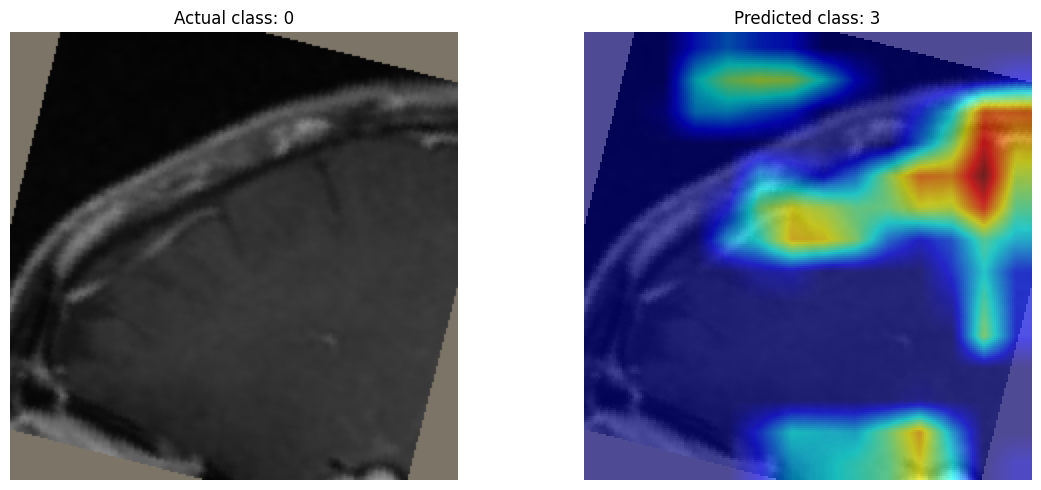

In [78]:
# Get one image from the batch
imgs, labels = next(iter(train_loader))

# Select one image
input_tensor = imgs[0:1].to(device)
label = labels[0].item()

# Predict
loaded_model.eval()

with torch.no_grad():
    outputs = loaded_model(input_tensor)

predicted_class = outputs.argmax(dim=1).item()

# Apply Grad-CAM
targets = [ClassifierOutputTarget(predicted_class)]

grayscale_cam = cam(
    input_tensor=input_tensor,
    targets=targets
)[0]

# Convert the image back to display format
# Replace these values with your training normalization values
mean = np.array([0.485, 0.456, 0.406])
std = np.array([0.229, 0.224, 0.225])

img = imgs[0].cpu().permute(1, 2, 0).numpy()
rgb_img = np.clip(img * std + mean, 0, 1).astype(np.float32)

# Overlay Grad-CAM
visualization = show_cam_on_image(
    rgb_img,
    grayscale_cam,
    use_rgb=True
)

# Display results
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(rgb_img)
plt.title(f"Actual class: {label}")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(visualization)
plt.title(f"Predicted class: {predicted_class}")
plt.axis("off")

plt.tight_layout()
plt.show()